In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import config as c
import numpy as np

In [2]:
sns.set_context("notebook")
sns.set_style("whitegrid")
sns.set_theme(

    rc={"font.family": "sans-serif", "font.sans-serif": ["Arial", "Helvetica", "DejaVu Sans"],

        "axes.labelsize": 13,
        "axes.titlesize": 15,
        "xtick.labelsize": 11,
        "ytick.labelsize": 11,
        "legend.fontsize": 11,
        "legend.title_fontsize": 12,

        "axes.spines.top": False,
        "axes.spines.right": False,
        "axes.linewidth": 1.0})

This metadata file records technical information about signals that passed coninous signal DP, but not all passed windowed signal DP.

## upload metadata & have a first look

In [3]:
filepath = f"{c.META_DIR}/exams_processed_technical_info.csv"
df = pd.read_csv(filepath, encoding = 'utf-8')
df

,site,exam_id,initial_fs,n_all_windows,ch_non_eeg,status,ch_drop,n_good_windows,why_bad_windows
0,S00,20220512-162946-{3ad3c86b-3d61-440e-81df-b74fd...,250.0,163,"[""ECG"", ""RESP1"", ""RESP2""]",ok,"[""S8"", ""S9"", ""S1"", ""S2""]",163,{}
1,S00,20220512-162858-{7dcc3e99-80fa-490b-99b0-6334c...,250.0,150,"[""ECG"", ""RESP1"", ""RESP2""]",too short,"[""S8"", ""S9"", ""S1"", ""S2""]",149,"{'Fp1': 1, 'Fp2': 1}"
2,S00,20220512-163059-{c7e51449-0539-4208-9962-61bd1...,250.0,150,"[""ECG"", ""RESP1"", ""RESP2""]",ok,[],150,{}
3,S00,20220512-162502-{e7d9d501-f72e-4045-afaf-d8827...,250.0,160,"[""ECG"", ""RESP1"", ""RESP2""]",ok,[],158,"{'T4': 1, 'Fp2': 1, 'Fz': 1}"
4,S00,20220512-170457-{f141a0b0-1275-435f-9cf1-4ead3...,250.0,450,"[""ECG"", ""RESP1"", ""RESP2""]",ok,[],446,"{'F7': 2, 'O1': 1, 'C3': 1, 'T3': 1, 'Fp1': 1}"
...,...,...,...,...,...,...,...,...,...
39660,S29,20220602-152610-{7008a1d7-3ce6-4a20-9b1c-3df5a...,250.0,201,[],ok,"[""EKG""]",201,{}
39661,S29,20220602-152655-{f7a40810-55c6-4f15-a461-76758...,250.0,200,[],ok,"[""A1"", ""A2"", ""EKG""]",200,{}
39662,S29,20220602-152850-{7f63b022-3c53-4b2c-80ff-69e79...,250.0,201,[],ok,[],201,{}
39663,S29,20220602-152230-{f52ece77-e74b-493c-9524-beec6...,250.0,202,[],ok,"[""A1"", ""A2"", ""EKG""]",200,{'Fp1': 2}


In [6]:
df.columns = df.columns.str.strip()

initial_fs_by_site = df.groupby("site")["initial_fs"].agg(
    ["mean", "min", "max"]
)

initial_fs_by_site

,mean,min,max
site,,,
S00,250.024017,249.987501,251.000000
S01,250.004789,250.000000,251.000000
S02,249.987501,249.987501,249.987501
S03,250.000000,250.000000,250.000000
S04,250.000000,250.000000,250.000000
S05,275.013333,250.000000,300.000000
S06,250.000000,250.000000,250.000000
S07,261.451116,250.000000,600.000000
S08,250.000000,250.000000,250.000000


All recordings were downsampled to fs = 128Hz.

Text(0.5, 1.03, 'Distribution of preprocessed full lengths in windows')

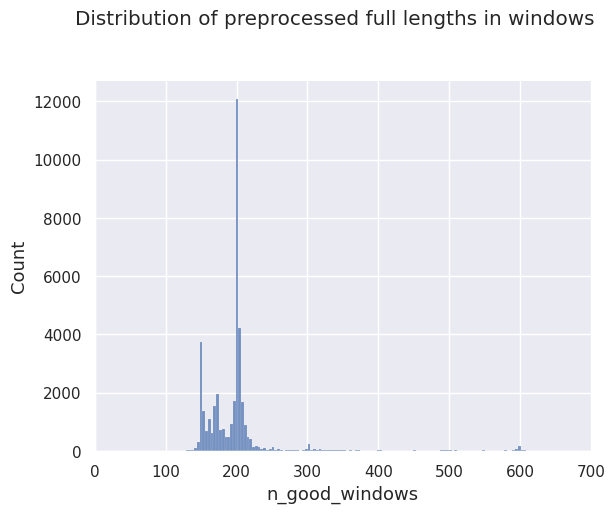

In [11]:
g = sns.histplot(x='n_good_windows', 
                data = df,
                )
g.set(xlim=(0, 700))
g.figure.suptitle('Distribution of preprocessed full lengths in windows', y = 1.03)